In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uncertainties

In [46]:
df = pd.read_csv("run_40K.csv")
df.head()

,V_Copper,V_Sapphire,time,sensor_temperature,temperature_setpoint,iTC_P_param,iTC_I_param,iTC_D_param
0,-0.000009,-0.000002,0.000000,40.0063,40.0,2.0,1.0,0.0
1,-0.000009,-0.000002,0.217953,40.0063,40.0,2.0,1.0,0.0
2,-0.000009,-0.000002,0.461550,40.0031,40.0,2.0,1.0,0.0
3,-0.000009,-0.000001,0.720548,40.0037,40.0,2.0,1.0,0.0
4,-0.000009,-0.000001,0.960529,40.0051,40.0,2.0,1.0,0.0


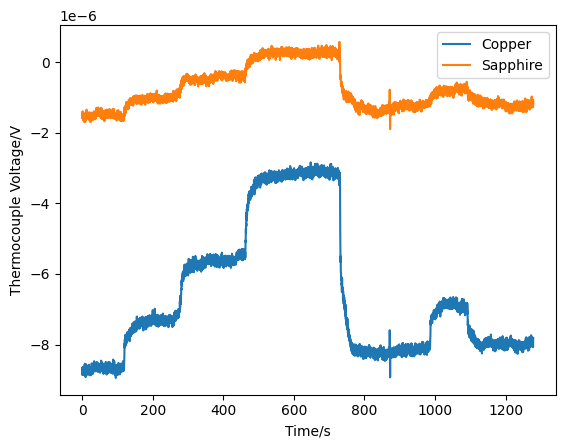

In [47]:
time = df['time']
v_cop = df['V_Copper']
v_sap = df['V_Sapphire']

plt.plot(time, v_cop, label = 'Copper')
plt.plot(time, v_sap, label = 'Sapphire')
plt.legend()
plt.xlabel("Time/s")
plt.ylabel("Thermocouple Voltage/V")
plt.show()

In [48]:
windows15K = {
    "V_Copper":   [(0, 118), (155, 228), (260, 395), (440, 612), (660, 770)],
    "V_Sapphire": [(0, 118), (145, 228), (255, 395), (425, 612), (660, 770)],
}

windows20K = {
    "V_Copper":   [(0, 105), (175, 238), (285, 365), (420, 498), (630, 670)],
    "V_Sapphire": [(0, 105), (140, 238), (270, 365), (390, 498), (620, 670)],
}

windows30K = {
    "V_Copper":   [(0, 115), (200, 292), (340, 430), (500, 670), (725, 855)],
    "V_Sapphire": [(0, 115), (190, 292), (330, 430), (500, 670), (725, 855)],
}

windows40K = {
    "V_Copper":   [(0, 110), (175, 262), (320, 415), (520, 715), (800, 970)],
    "V_Sapphire": [(0, 110), (170, 255), (300, 450), (510, 715), (860, 970)],
}

windows = windows40K

v_avg = {}
v_std = {}

for material, times in windows.items():
    print(material)
    v_avg[material] = []
    v_std[material] = []
    for start, end in times:
        in_window = (time >= start) & (time <= end)
        average = df.loc[in_window, material].mean()
        std = df.loc[in_window, material].std()
        v_avg[material].append(average)
        v_std[material].append(std)
        print(f"  {start}-{end} s: {average:.4e} +- {std:.4e} V")

V_Copper
  0-110 s: -8.6854e-06 +- 8.6507e-08 V
  175-262 s: -7.3254e-06 +- 9.3222e-08 V
  320-415 s: -5.6628e-06 +- 9.6866e-08 V
  520-715 s: -3.1710e-06 +- 1.0879e-07 V
  800-970 s: -8.2032e-06 +- 1.0820e-07 V
V_Sapphire
  0-110 s: -1.5052e-06 +- 8.0400e-08 V
  170-255 s: -1.0364e-06 +- 7.3790e-08 V
  300-450 s: -4.4737e-07 +- 9.2513e-08 V
  510-715 s: 2.5999e-07 +- 7.6761e-08 V
  860-970 s: -1.2604e-06 +- 9.7796e-08 V


In [49]:
baseline = {
    "V_Copper": v_avg["V_Copper"][0],
    "V_Sapphire": v_avg["V_Sapphire"][0]
}

v_avg_adj = {}

for material in v_avg.keys():
    v_avg_adj[material] = []
    #print(material)
    for i in range(1, len(v_avg[material])-1):
        v_avg_adj[material].append(v_avg[material][i]-baseline[material])
for material, values in v_avg_adj.items():
    print(material)
    output = "[0,"
    std_output = f"[{v_std[material][0]},"
    for i, v in enumerate(values, start=1):
        #print(f"  Step {i}: {v:.4e} V")
        output = output + f"{v}"
        std_output = std_output + f"{v_std[material][i-1]}"
        if i != len(values):
            output = output+","
            std_output = std_output+","
    output = output + "]"
    std_output = std_output + "]"
    print(output)
    print(std_output)



V_Copper
[0,1.3600675039423397e-06,3.0226772904904764e-06,5.514422103748541e-06]
[8.650746552330928e-08,8.650746552330928e-08,9.322151213697913e-08,9.686598803106015e-08]
V_Sapphire
[0,4.688070026801076e-07,1.0578074818535146e-06,1.76516727181018e-06]
[8.039971120593082e-08,8.039971120593082e-08,7.379000531973439e-08,9.251295425236258e-08]


In [50]:
# --- Baseline-drift correction: straight line between the two baselines ---
v_avg_drift = {}

for material, times in windows.items():
    # midpoint times of every window
    t_mid = [(start + end) / 2 for start, end in times]

    # straight line through (t_first, V_first) and (t_last, V_last)
    t0, t1 = t_mid[0], t_mid[-1]
    v0, v1 = v_avg[material][0], v_avg[material][-1]
    gradient = (v1 - v0) / (t1 - t0)

    def baseline_line(t):
        return v0 + gradient * (t - t0)

    # subtract the line's value at each intermediate step's midpoint
    v_avg_drift[material] = [0]
    for i in range(1, len(times) - 1):
        v_avg_drift[material].append(float(v_avg[material][i] - baseline_line(t_mid[i])))

for material, values in v_avg_drift.items():
    print(material)
    output = "[" + ",".join(f"{v}" for v in values) + "]"
    std_output = "[" + ",".join(f"{v_std[material][i]}" for i in range(len(values))) + "]"
    print(output)
    print(std_output)

V_Copper
[0,1.265062152427356e-06,2.8410921385122955e-06,5.187568830187814e-06]
[8.650746552330928e-08,9.322151213697913e-08,9.686598803106015e-08,1.087917050747741e-07]
V_Sapphire
[0,4.239737477740865e-07,9.667176941079482e-07,1.606471782222201e-06]
[8.039971120593082e-08,7.379000531973439e-08,9.251295425236258e-08,7.676141588179177e-08]
